# Missing data in VaDeSC

First experiments with survival models that handle missing features, including informative missingness (MAR, MNAR).

1. How much is missing in SUPPORT, and is missingness related to survival?
2. A missingness-aware VaDeSC, following Collier et al. (2020), *VAEs in the presence of missing data*
3. Simulated data with known clusters and controlled missingness (MCAR, MAR, MNAR)
4. Missingness that depends on survival, and modelling the mask in the latent space
5. SUPPORT with its real missingness

Takes roughly 30-40 min on a CPU. `QUICK = True` for a short check.

In [1]:
import sys
sys.path.append("..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import adjusted_rand_score

from src.baselines import run_cox
from src.data import SUPPORT_DROP, SUPPORT_POST_BASELINE, load_support, load_support_raw
from src.missing import MissVaDeSC, fill_and_mask, simulate_splits
from src.vadesc import evaluate_vadesc, train_vadesc

QUICK = False
SEEDS = [0, 1] if QUICK else [0, 1, 2, 3, 4]
SIM_EPOCHS = 50 if QUICK else 100
SUPPORT_EPOCHS = 60 if QUICK else 300
SUPPORT_SEEDS = [0] if QUICK else [0, 1, 2]

## 1. Missingness in SUPPORT

Only variables known at study entry (the post-baseline variables are removed, see notebook 01).

In [2]:
raw = load_support_raw()
X = raw.drop(columns=SUPPORT_DROP + SUPPORT_POST_BASELINE)
print(f"patients with at least one missing value: {X.isna().any(axis=1).mean():.0%}")

miss = X.isna().mean().sort_values(ascending=False)
miss = miss[miss >= 0.01]  # ignore features with only a handful of missing values
rows = []
for c in miss.index:
    m = X[c].isna()
    rows.append({"feature": c, "missing": m.mean(),
                 "death rate if missing": raw["death"][m].mean(),
                 "death rate if measured": raw["death"][~m].mean()})
pd.DataFrame(rows).set_index("feature").round(2)

patients with at least one missing value: 95%


,missing,death rate if missing,death rate if measured
feature,,,
adlp,0.62,0.73,0.61
urine,0.53,0.73,0.62
glucose,0.49,0.74,0.62
bun,0.48,0.75,0.62
alb,0.37,0.69,0.67
income,0.33,0.71,0.67
adls,0.31,0.72,0.66
bili,0.29,0.68,0.68
pafi,0.26,0.72,0.67


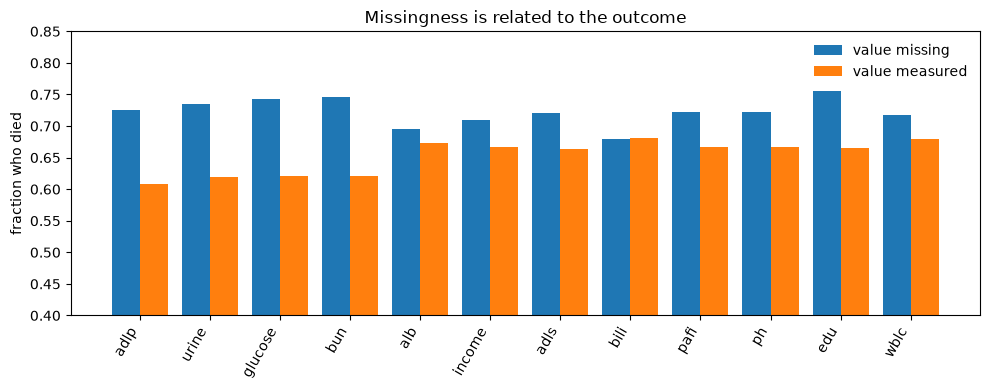

In [3]:
fig, ax = plt.subplots(figsize=(10, 4))
t = pd.DataFrame(rows).set_index("feature")
x = np.arange(len(t))
ax.bar(x - 0.2, t["death rate if missing"], 0.4, label="value missing")
ax.bar(x + 0.2, t["death rate if measured"], 0.4, label="value measured")
ax.set_xticks(x, t.index, rotation=60, ha="right")
ax.set(ylabel="fraction who died", ylim=(0.4, 0.85), title="Missingness is related to the outcome")
ax.legend(frameon=False); plt.tight_layout(); plt.show()

## 2. Models

All inputs are standardised with training statistics, so filling a missing value with 0 means filling it with the training mean.

| | input | reconstruction loss |
|---|---|---|
| **VaDeSC (mean imp.)** | values, missing set to the mean | all values, including the filled-in ones |
| **VaDeSC (+mask input)** | values and the 0/1 mask as extra features | all values and the mask |
| **MissVaDeSC** | values and mask | observed values only |
| **MissVaDeSC + mask model** | values and mask | observed values, plus a decoder for the mask $p(m \mid z)$ |

MissVaDeSC follows Collier et al.: the encoder sees the mask and the model is only asked to reconstruct what was observed. The mask model lets the latent space, and so the clusters, depend on which features were measured. Cox with mean imputation and Cox with the mask as extra features are the simple references.

In [2]:
order = ["Cox (mean imp.)", "Cox (+mask)", "VaDeSC (mean imp.)", "VaDeSC (+mask input)", "MissVaDeSC", "MissVaDeSC + mask model"]


def run_all(ds, K, d_lat, weibull_k, epochs, seed, c_te=None):
    # Same (small) network for every VaDeSC variant: with the mask, SUPPORT has 106 inputs,
    # which would otherwise switch to the wide network used for p > 100.
    d0, d1 = fill_and_mask(ds, False), fill_and_mask(ds, True)
    out = [{"method": "Cox (mean imp.)", **run_cox(d0)},
           {"method": "Cox (+mask)", **run_cox(d1)}]
    variants = [
        ("VaDeSC (mean imp.)", d0, {"model_kwargs": {"net": "small"}}),
        ("VaDeSC (+mask input)", d1, {"model_kwargs": {"net": "small"}}),
        ("MissVaDeSC", d1, {"model_cls": MissVaDeSC, "model_kwargs": {"model_mask": False, "net": "small"}}),
        ("MissVaDeSC + mask model", d1, {"model_cls": MissVaDeSC, "model_kwargs": {"model_mask": True, "net": "small"}}),
    ]
    for name, d, kw in variants:
        model = train_vadesc(d, K=K, d_lat=d_lat, weibull_k=weibull_k, epochs=epochs, seed=seed, **kw)
        m, clusters, _ = evaluate_vadesc(model, d)
        if c_te is not None:
            m["ARI"] = adjusted_rand_score(c_te, clusters)
        out.append({"method": name, **m})
    return out

## 3. Simulated data with controlled missingness

Official VaDeSC generator (`src/simulate.py`): 3 clusters, latent variables mapped to covariates by a random MLP, cluster-specific Weibull survival, with 6,000 patients and 30 features. The clusters are more separated than in the paper (cluster means in [-2, 2] instead of [-0.5, 0.5]), because with this sample size the paper's setting is too hard to recover even without missing data.

30% of the values are then removed:
- **MCAR**: completely at random
- **MAR**: in half of the features, missingness depends on another, always observed feature
- **MNAR**: large values are more likely to be missing (self-masking)

In [5]:
rows = []
for mech in ["none", "MCAR", "MAR", "MNAR"]:
    for seed in SEEDS:
        ds, c_te = simulate_splits(seed=seed, mechanism=mech, xrange=(-2, 2))
        for r in run_all(ds, K=3, d_lat=8, weibull_k=1.0, epochs=SIM_EPOCHS, seed=seed, c_te=c_te):
            rows.append({"mechanism": mech, "seed": seed, **r})
sim = pd.DataFrame(rows)
summary = sim.groupby(["method", "mechanism"])[["C-index", "IBS", "ARI"]].agg(["mean", "std"])
summary.reindex(order, level=0).round(3)

C-index           IBS           ARI       
                                     mean    std   mean    std   mean    std
method                  mechanism                                           
Cox (mean imp.)         MAR         0.729  0.025  0.180  0.009    NaN    NaN
                        MCAR        0.695  0.035  0.192  0.011    NaN    NaN
                        MNAR        0.696  0.033  0.193  0.009    NaN    NaN
                        none        0.727  0.026  0.180  0.011    NaN    NaN
Cox (+mask)             MAR         0.729  0.025  0.180  0.009    NaN    NaN
                        MCAR        0.691  0.035  0.193  0.011    NaN    NaN
                        MNAR        0.727  0.031  0.181  0.010    NaN    NaN
                        none        0.727  0.026  0.180  0.011    NaN    NaN
VaDeSC (mean imp.)      MAR         0.727  0.013  0.181  0.007  0.395  0.115
                        MCAR        0.714  0.022  0.185  0.008  0.361  0.100
                        MNAR        0.715  0.026  0.186  0.012  0.374  0.078
                        none        0.743  0.013  0.175  0.006  0.536  0.198
VaDeSC (+mask input)    MAR         0.704  0.045  0.190  0.014  0.526  0.131
                        MCAR        0.702  0.030  0.188  0.009  0.440  0.093
                        MNAR        0.711  0.030  0.184  0.011  0.430  0.109
                        none        0.720  0.025  0.181  0.008  0.511  0.179
MissVaDeSC              MAR         0.715  0.038  0.184  0.014  0.458  0.192
                        MCAR        0.718  0.028  0.184  0.013  0.486  0.130
                        MNAR        0.729  0.026  0.179  0.009  0.439  0.104
                        none        0.738  0.025  0.176  0.008  0.578  0.163
MissVaDeSC + mask model MAR         0.706  0.039  0.186  0.013  0.461  0.207
                        MCAR        0.712  0.027  0.186  0.013  0.492  0.141
                        MNAR        0.711  0.030  0.186  0.011  0.432  0.109
                        none        0.738  0.022  0.176  0.008  0.573  0.165

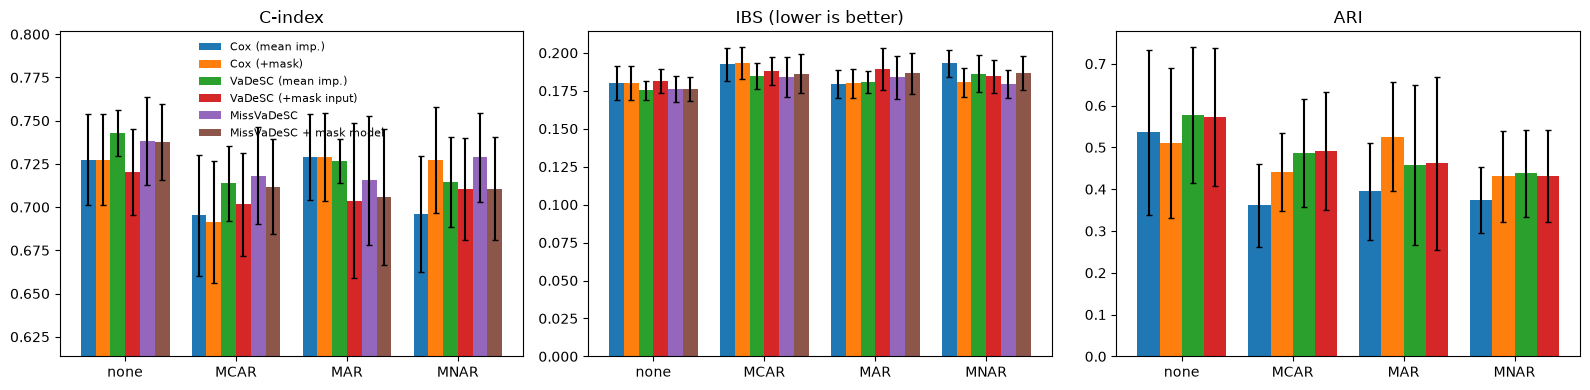

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
mechs = ["none", "MCAR", "MAR", "MNAR"]
for a, metric in zip(ax, ["C-index", "IBS", "ARI"]):
    methods = [m for m in order if sim.loc[sim.method == m, metric].notna().any()]
    w = 0.8 / len(methods)
    for i, m in enumerate(methods):
        g = sim[sim.method == m].groupby("mechanism")[metric]
        a.bar(np.arange(4) + i * w, g.mean().reindex(mechs), w, yerr=g.std().reindex(mechs), label=m, capsize=2)
    a.set_xticks(np.arange(4) + 0.4 - w / 2, mechs)
    a.set(title=metric + (" (lower is better)" if metric == "IBS" else ""))
lo = sim["C-index"].min() - 0.03
ax[0].set_ylim(lo, None)
ax[0].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

## 4. Missingness that depends on survival

Idea: long and short survivors have different features missing, so the missingness pattern itself carries information about survival. Modelling the mask from the latent variable, $p(m \mid z)$, should then let the missingness shape the embedding.

Simulation: in the first half of the features, long survivors are more often missing; in the second half, short survivors are (based on the true event time). 30% missing overall, at two strengths:
- **weak** (`strength=1`): missingness is only mildly related to survival
- **strong** (`strength=3`): in the first half of the features, 48% of the values are missing for patients who survive longer than the median vs 12% for the others (seed 0)

In [7]:
rows = []
for strength in [1.0, 3.0]:
    for seed in SEEDS:
        ds, c_te = simulate_splits(seed=seed, mechanism="survival", strength=strength, xrange=(-2, 2))
        for r in run_all(ds, K=3, d_lat=8, weibull_k=1.0, epochs=SIM_EPOCHS, seed=seed, c_te=c_te):
            rows.append({"strength": strength, "seed": seed, **r})
surv_miss = pd.DataFrame(rows)
surv_miss.groupby(["method", "strength"])[["C-index", "IBS", "ARI"]].agg(["mean", "std"]).reindex(order, level=0).round(3)

C-index           IBS           ARI       
                                    mean    std   mean    std   mean    std
method                  strength                                           
Cox (mean imp.)         1.0        0.681  0.039  0.198  0.011    NaN    NaN
                        3.0        0.659  0.047  0.205  0.010    NaN    NaN
Cox (+mask)             1.0        0.824  0.020  0.142  0.013    NaN    NaN
                        3.0        0.898  0.015  0.088  0.012    NaN    NaN
VaDeSC (mean imp.)      1.0        0.753  0.019  0.172  0.007  0.368  0.098
                        3.0        0.805  0.023  0.138  0.009  0.378  0.088
VaDeSC (+mask input)    1.0        0.806  0.026  0.145  0.010  0.471  0.119
                        3.0        0.867  0.025  0.103  0.012  0.289  0.110
MissVaDeSC              1.0        0.784  0.012  0.153  0.009  0.478  0.153
                        3.0        0.845  0.024  0.113  0.018  0.499  0.162
MissVaDeSC + mask model 1.0        0.817  0.023  0.142  0.008  0.473  0.070
                        3.0        0.881  0.016  0.096  0.010  0.420  0.159

## 5. SUPPORT with its real missingness

Baseline-only features, missing values kept, 4 clusters as in the paper's config.

In [3]:
support = load_support(drop_post_baseline=True, keep_missing=True)
print(f"missing entries in the training features: {np.isnan(support.X_tr).mean():.1%}")
rows = []
for seed in SUPPORT_SEEDS:
    for r in run_all(support, K=4, d_lat=16, weibull_k=2.0, epochs=SUPPORT_EPOCHS, seed=seed):
        rows.append({"seed": seed, **r})
sup = pd.DataFrame(rows)
sup.groupby("method")[["C-index", "IBS", "log-rank chi2"]].agg(["mean", "std"]).reindex(order).round(3)

missing entries in the training features: 7.2%


C-index           IBS        log-rank chi2        
                           mean    std   mean    std          mean     std
method                                                                    
Cox (mean imp.)           0.733  0.000  0.174  0.000           NaN     NaN
Cox (+mask)               0.734  0.000  0.175  0.000           NaN     NaN
VaDeSC (mean imp.)        0.688  0.018  0.189  0.004       419.795  49.201
VaDeSC (+mask input)      0.658  0.012  0.198  0.004       369.906  46.258
MissVaDeSC                0.683  0.008  0.191  0.001       423.063  41.776
MissVaDeSC + mask model   0.657  0.007  0.200  0.004       369.494  29.431

## Notes

- One data split per setting; seeds vary model initialisation (and the simulated dataset). Differences of about 0.01-0.02 in C-index are within the noise.
- The mask model here is a simple Bernoulli decoder $p(m \mid z)$. Collier et al. model the corruption process more generally; a closer implementation, and MNAR-specific models (e.g. not-MIWAE), are next steps.
- Not covered here: multiple imputation (MICE) as a baseline, SurvivalPFN as a baseline, other missingness rates.
- In section 4 the mask is very informative (Cox with the mask as features is much better than with mean imputation). The VaDeSC variants that see the mask improve a lot too, and modelling the mask helps most with strong informative missingness, but Cox with the mask is still the best. The survival term is a single likelihood term next to the reconstruction of all features (and the mask), so the latent space is mostly organised by those. Possible next steps: weight the survival term, or let the survival head see the mask directly.
- Sections 3 and 4 use the official simulation code (`src/simulate.py`); section 5 does not use simulated data.
- On SUPPORT (section 5) the mask does not help: Cox is the same with and without it, and the VaDeSC variants that reconstruct the mask or model it are about 0.03 worse in C-index. All VaDeSC variants use the same small network (`net="small"`); with the mask SUPPORT has 106 inputs, which would otherwise switch to the wide network.
